<a href="https://colab.research.google.com/github/comet-toolkit/comet_training/blob/main/meteor_sat2insitu_example.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MetEOR toolkit example: comparing Sentinel-2A with the RadCalNet GONA site**

This notebook demonstrates the satellite-insitu comparison workflow underpinned by the [MetEOR toolkit](https://github.com/meteor-toolkit):
1. **Finding overpasses** of a satellite over the in-situ site
2. **Reading** both satellite and in-situ datasets
3. **Preparing the datasets for comparison** including *uncertainty propagation* (i.e. spectral band alignment, averaging image data over the site region of interest (ROI))
3. **Compare observations** *with uncertainties*.

As a worked example in this notebook we compare Sentinel-2A top-of-atmosphere (TOA) reflectance with the RadCalNet site at Gobabeb, Namibia (site code GONA), for a single clear-sky overpass.

The workflow uses four tools from the open-source [MetEOR toolkit](https://github.com/meteor-toolkit):

| Tool | Role in this notebook |
|---|---|
| [`scrappi`](https://github.com/meteor-toolkit/scrappi) | queries the satellite and in-situ archives and downloads products |
| [`eomatch`](https://github.com/meteor-toolkit/eomatch) | finds the collocated satellite/in-situ products and catalogues them as matchups |
| [`eoio`](https://github.com/meteor-toolkit/eoio) | reads the products into `xarray` datasets, including uncertainties where available |
| [`meteor_maths`](https://github.com/meteor-toolkit/meteor_maths) | band-integrates the in-situ spectrum over the satellite spectral response functions |

**How this notebook runs**

Downloading Sentinel-2 and RadCalNet data needs (free) accounts. If you fill in your credentials in the first code cell below, every step runs live. If you leave them as they are, the only steps that cannot run, searching the archives for matchups and downloading the products, are replaced by a pre-computed copy of their results: the matchup catalogue and the downloaded products. Every other step runs exactly the same in both cases.

We first install and import the packages we need. (If Colab asks you to restart the runtime after the install, do so and then run the notebook from the top.)

In [1]:
!pip install -q eomatch eoio meteor_maths s2_rut_python punpy scrappi

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


**Credentials and data access**

To run live you need a [Copernicus Data Space](https://dataspace.copernicus.eu) account (for Sentinel-2) and a [RadCalNet](https://www.radcalnet.org) account. On Colab, the safest place to keep the necessary credentials is *Secrets* (the key icon in the left sidebar): add `CDSE_USERNAME`, `CDSE_PASSWORD`, `RADCALNET_USERNAME` and `RADCALNET_PASSWORD`, and switch on notebook access. Alternatively, replace the `YOUR_...` placeholders below (just don't share the notebook afterwards!).

The credentials are only passed on to the tools in memory, through the `eomatch` context, and are not written to disk (including in the matchup catalogue).

In [2]:
import datetime
import logging
import os
import pathlib
import shutil
import urllib.request
import warnings

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import sys; sys.prefix = "/nonexistent"  # TEMPORARY, only to test the PROJ diagnosis

# show the progress messages of eomatch, and hide the (very verbose) ones of eodag
logging.basicConfig(level=logging.WARNING)
logging.getLogger("eomatch").setLevel(logging.INFO)
logging.getLogger("eodag").setLevel(logging.WARNING)
logging.getLogger("eomatch.utils.crop").setLevel(logging.ERROR)
logging.getLogger("pyspectral").setLevel(logging.ERROR)

# hide some harmless warnings of the dependencies, but not the ones that report a failed query
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings(
    "ignore",
    message=".*(EODAG you are using|No credentials found for (earthaccess|eumdac)|Duplicate dimension names present"
    "|'where' used without 'out'|missing expected metadata key|credentials could not be set in environment).*",
)

# --- credentials: Colab secrets first, then these placeholders ---------------------------
CREDENTIALS = {
    "CDSE_USERNAME": "YOUR_COPERNICUS_DATASPACE_USERNAME",
    "CDSE_PASSWORD": "YOUR_COPERNICUS_DATASPACE_PASSWORD",
    "RADCALNET_USERNAME": "YOUR_RADCALNET_USERNAME",
    "RADCALNET_PASSWORD": "YOUR_RADCALNET_PASSWORD",
}

try:
    from google.colab import userdata

    for name in CREDENTIALS:
        try:
            CREDENTIALS[name] = userdata.get(name)
        except Exception:  # secret not set (or notebook access not granted)
            pass
except ImportError:  # not running on Colab
    for name in CREDENTIALS:
        CREDENTIALS[name] = os.environ.get(name, CREDENTIALS[name])

LIVE = not any(value.startswith("YOUR_") for value in CREDENTIALS.values())

WORKDIR = pathlib.Path("meteor_sat2insitu_work")
WORKDIR.mkdir(exist_ok=True)
CATALOGUE_DIR = str(WORKDIR / "catalogue")

if not LIVE:
    # --- pre-computed matchup catalogue and products, used when no credentials are given -----
    CACHE_URL = "https://github.com/comet-toolkit/comet_training/releases/download/meteor-sat2insitu-data"

    def fetch_cached_catalogue():
        """Download and unpack the pre-computed matchup catalogue, with the products it points to."""
        archive = WORKDIR / "catalogue.zip"
        if not archive.exists():
            urllib.request.urlretrieve(f"{CACHE_URL}/catalogue.zip", archive)
        shutil.unpack_archive(archive, CATALOGUE_DIR)


print("Running LIVE with your credentials." if LIVE else "No credentials found: using the pre-computed catalogue and products.")

Running LIVE with your credentials.


## 1. Finding overpasses of a satellite over the in-situ site
**Defining the comparison**

An `eomatch` comparison is defined by a context (a configuration), which can be a YAML file or, as here, a dictionary. We compare Sentinel-2A (`S2A`, collection `S2_MSI_L1C`) with the RadCalNet GONA site (collection `RCN_TOA`, which has TOA reflectance), for one day in May 2026.

In [3]:
from eomatch import EOMatchContext

SITE = "GONA"

config = {
    "platforms": f"S2A, {SITE}",
    "collections": "S2_MSI_L1C, RCN_TOA",
    "start_time": "2026-05-15 00:00:00",
    "end_time": "2026-05-16 00:00:00",
    "time_diff_threshold": 3600,  # max time between the S2 overpass and the RadCalNet product [s]
    "matchup_catalogue": {"path": CATALOGUE_DIR},
}
if LIVE:
    # the credentials, for scrappi's RadCalNet and Copernicus Data Space (through eodag) handlers
    config["RadCalNet"] = {
        "credentials": {"username": CREDENTIALS["RADCALNET_USERNAME"], "password": CREDENTIALS["RADCALNET_PASSWORD"]}
    }
    config["eodag"] = {
        "cop_dataspace": {
            "auth": {"credentials": {"username": CREDENTIALS["CDSE_USERNAME"], "password": CREDENTIALS["CDSE_PASSWORD"]}}
        }
    }

context = EOMatchContext(config)

if LIVE:
    # TEMPORARY, until fixed in scrappi: scrappi builds its eodag handler once and reuses it, and the first one it
    # builds (inside the finder, only to check a collection) has no credentials. Build it here with ours instead.
    import scrappi

    scrappi.make_api("eodag", context=scrappi.ScrappiContext(config))

print(context["platforms"], "|", context["collections"])

Initialising config at /root/.config/eomatch...
Initialising config at /root/.config/scrappi...
S2A, GONA | S2_MSI_L1C, RCN_TOA


**eomatch: finding and cataloguing the matchups**

`find_and_catalogue_insitu` runs the discovery step. `eomatch` uses `scrappi` underneath to search for products: RadCalNet sites have a registered region of interest (ROI), which we use to search for Sentinel-2 products covering the site, and we then query RadCalNet itself for the site's data files in the same time window. The Sentinel-2 overpasses are grouped into events, the geometric overlap with the in-situ site is checked, and each matchup is stored as an item in a local STAC catalogue. Without credentials we open the catalogue that this step produced earlier instead.

In [4]:
from eomatch import MatchupCatalogue

if LIVE:
    from eomatch.find_and_catalogue import find_and_catalogue_insitu

    find_and_catalogue_insitu(context=context, path=CATALOGUE_DIR)
else:
    fetch_cached_catalogue()

INFO:eomatch.find_and_catalogue:Running Sat2InSituMUFinder...
INFO:eodag.provider:Loading user configuration from: /root/.config/eodag/eodag.yml
INFO:eodag.core:aws_eos: provider needing auth for search has been pruned because no credentials could be found
INFO:eodag.core:cop_ads: provider needing auth for search has been pruned because no credentials could be found
INFO:eodag.core:cop_cds: provider needing auth for search has been pruned because no credentials could be found
INFO:eodag.core:cop_dataspace_s3: provider needing auth for search has been pruned because no credentials could be found
INFO:eodag.core:cop_ewds: provider needing auth for search has been pruned because no credentials could be found
INFO:eodag.core:creodias_s3: provider needing auth for search has been pruned because no credentials could be found
INFO:eodag.core:dedl: provider needing auth for search has been pruned because no credentials could be found
INFO:eodag.core:dedt_leonardo: provider needing auth for sea


Below we summarise the result: which products were matched, how far apart in time they are, and the size of the collocation region.

The site is covered by two overlapping Sentinel-2 tiles, which gives one matchup per tile. We continue with the one with the largest collocation region, and remove the other from the catalogue so that its product is not downloaded.


In [5]:
catalogue = MatchupCatalogue.open(CATALOGUE_DIR, context=context)

events = catalogue.get_events()
if not events:
    raise RuntimeError(
        "No matchups found. Look for warnings above (e.g. about a failed RadCalNet or Copernicus query), "
        "and check your credentials and the time window."
    )
event = events[0]
matchup = max(event.matchup_set, key=lambda m: m.collocation_region.area)
for other in event.matchup_set:
    if other.stac_id != matchup.stac_id:
        catalogue.remove_matchup(other.stac_id)

print(f"Event:   {event.stac_id}")
print(f"Matchup: {matchup.stac_id}")
for p in matchup.products:
    print(f"  {p.collection:<12} {p.platform:<5} {p.start_time}  {p.id}")

INFO:eomatch.mu_stac:Removed matchup item file /content/meteor_sat2insitu_work/catalogue/RCN_TOA-GONA-vs-S2_MSI_L1C-S2A/2026/5/15/RCN_TOA-GONA-vs-S2_MSI_L1C-S2A_20260515T084731_9b3c48b608.json


Event:   RCN_TOA-GONA-vs-S2_MSI_L1C-S2A_20260515T074731
Matchup: RCN_TOA-GONA-vs-S2_MSI_L1C-S2A_20260515T084731_3656eb5ee3
  RCN_TOA      GONA  2026-05-15 07:59:31.306560+00:00  GONA01_2026_135_v04.09.output
  S2_MSI_L1C   S2A   2026-05-15 08:47:31+00:00  S2A_MSIL1C_20260515T084731_N0512_R107_T33KWP_20260515T140818


**Downloading the products**

`download_products` fetches the Sentinel-2 L1C scene (around 800 MB) and the RadCalNet file for the matchup (if they are already on disk, as in the no-credentials mode, it just registers them).

In [6]:
catalogue.download_products()

GONA01_2026_135_v04.09.output needs downloading
Setting output directory for provider cop_dataspace to /content/meteor_sat2insitu_work/catalogue/data/Sentinel-2/S2A/S2_MSI_L1C/2026/05/15
S2A_MSIL1C_20260515T084731_N0512_R107_T33KWP_20260515T140818 needs downloading to /content/meteor_sat2insitu_work/catalogue/data/Sentinel-2/S2A/S2_MSI_L1C/2026/05/15


0.00B [00:00, ?B/s]

INFO:eodag.download.base:Download url: https://catalogue.dataspace.copernicus.eu/odata/v1/Products(3b5fc17b-cc3a-4b1f-9737-e02efdca9e7c)/$value
INFO:eodag.download.base:Extraction not activated. The product is available as is.
INFO:eodag.product:Remote location of the product is still available through its 'remote_location' property: https://catalogue.dataspace.copernicus.eu/odata/v1/Products(3b5fc17b-cc3a-4b1f-9737-e02efdca9e7c)/$value


['/content/meteor_sat2insitu_work/catalogue/data/RadCalNet/GONA/RCN_TOA/2026/05/15/GONA01_2026_135_v04.09.output/GONA01_2026_135_v04.09.output',
 '/content/meteor_sat2insitu_work/catalogue/data/Sentinel-2/S2A/S2_MSI_L1C/2026/05/15/S2A_MSIL1C_20260515T084731_N0512_R107_T33KWP_20260515T140818']

### 2. Reading the products and their uncertainties

`eomatch.return_matchup_dataset` reads both products over the collocation region using `eoio` and combines them into a single `xarray.DataTree`, with one node per product. Each node contains the measurements together with auxiliary data, uncertainty information, and associated metadata.

Uncertainties are read alongside the measurements:

- The RadCalNet reader returns both reflectance and its total uncertainty.
- For Sentinel-2, the `s2_rut` processor is applied during the read. This uses `s2_rut_python`, a python port of ESA's [Sentinel-2 Radiometric Uncertainty Tool](https://github.com/senbox-org/snap-rut), to generate per-pixel uncertainty estimates.

The Sentinel-2 uncertainty is provided as two components:

- **Systematic uncertainty**: fully correlated between pixels, representing errors that affect all pixels equally.
- **Random uncertainty**: independent between pixels, representing pixel-to-pixel variability.

Additional processors prepare the Sentinel-2 data for analysis:

- `add_lat_lon` adds latitude and longitude coordinates to every pixel.
- Solar zenith angle is interpolated onto the pixel grid for each resolution, as required by the uncertainty tool.
- `to_datatree` organises bands from each spatial resolution into separate `DataTree` nodes.

In [7]:
matchup = catalogue.get_events(products_downloaded=True)[0].matchup_set[0]  # the same matchup, now with its products on disk

# Define read parameters
S2_READ_ARGS = {
    "vars_sel": {"meas": "all", "aux": ["solar_zenith_angle"]},
    "read_params": {"use_chunks": True, "save_extracted": True, "ave_va_det": True},
    "processors": [
        {"add_lat_lon": {}},
        {
            "interpolate": {
                "coords": ["y_5000m", "x_5000m"],
                "data_vars": ["solar_zenith_angle"],
                "target_grid": [["y_10m", "y_20m", "y_60m"], ["x_10m", "x_20m", "x_60m"]],
                "method": "linear",
                "drop_original": True,
            }
        },
        {"s2_rut": {"data_vars": True, "group_unc": True}},
        {"to_datatree": {"grid_attr": "product_metadata.geometry_id"}},
    ],
}
RCN_READ_ARGS = {
    "vars_sel": {"meas": ["reflectance"], "aux": "all"},
    "processors": {"to_datatree": {"grid_attr": "product_metadata.geometry_id"}},
}

dt_mu = matchup.return_matchup_dataset(collection_read_args={"S2_MSI_L1C": S2_READ_ARGS, "RCN_TOA": RCN_READ_ARGS})
print(dt_mu)

GONA01_2026_135_v04.09.output needs downloading
Setting output directory for provider cop_dataspace to data/Sentinel-2/S2A/S2_MSI_L1C/2026/05/15
S2A_MSIL1C_20260515T084731_N0512_R107_T33KWP_20260515T140818 needs downloading to data/Sentinel-2/S2A/S2_MSI_L1C/2026/05/15


0.00B [00:00, ?B/s]

INFO:eodag.download.base:Download url: https://catalogue.dataspace.copernicus.eu/odata/v1/Products(3b5fc17b-cc3a-4b1f-9737-e02efdca9e7c)/$value
INFO:eodag.download.base:Extraction not activated. The product is available as is.
INFO:eodag.product:Remote location of the product is still available through its 'remote_location' property: https://catalogue.dataspace.copernicus.eu/odata/v1/Products(3b5fc17b-cc3a-4b1f-9737-e02efdca9e7c)/$value
/usr/local/lib/python3.13/dist-packages/scrappi/api/eodag.py:564: UserWarning: Downloaded product to /content/data/Sentinel-2/S2A/S2_MSI_L1C/2026/05/15/S2A_MSIL1C_20260515T084731_N0512_R107_T33KWP_20260515T140818.zip instead of expected data/Sentinel-2/S2A/S2_MSI_L1C/2026/05/15/S2A_MSIL1C_20260515T084731_N0512_R107_T33KWP_20260515T140818. Moving to expected location.
  warnings.warn(


data/Sentinel-2/S2A/S2_MSI_L1C/2026/05/15/S2A_MSIL1C_20260515T084731_N0512_R107_T33KWP_20260515T140818.SAFE extracted.


/usr/local/lib/python3.13/dist-packages/rioxarray/_spatial_utils.py:438: UserWarning: File object not available, clipping in-memory.
  warnings.warn("File object not available, clipping in-memory.")
/usr/local/lib/python3.13/dist-packages/rioxarray/_spatial_utils.py:438: UserWarning: File object not available, clipping in-memory.
  warnings.warn("File object not available, clipping in-memory.")
/usr/local/lib/python3.13/dist-packages/rioxarray/_spatial_utils.py:438: UserWarning: File object not available, clipping in-memory.
  warnings.warn("File object not available, clipping in-memory.")
/usr/local/lib/python3.13/dist-packages/rioxarray/_spatial_utils.py:438: UserWarning: File object not available, clipping in-memory.
  warnings.warn("File object not available, clipping in-memory.")
/usr/local/lib/python3.13/dist-packages/rioxarray/_spatial_utils.py:438: UserWarning: File object not available, clipping in-memory.
  warnings.warn("File object not available, clipping in-memory.")
/usr/

<xarray.DataTree>
Group: /
│   Attributes: (12/13)
│       date_created:                    2026-11-20T09:34:30.167452+00:00
│       end_datetime:                    2026-05-15T13:59:31.306560+00:00
│       matchup:collections:             ['RCN_TOA', 'S2_MSI_L1C']
│       matchup:platforms:               ['GONA', 'S2A']
│       matchup:time_diff_abs:           2879.69344
│       matchup:event_id:                RCN_TOA-GONA-vs-S2_MSI_L1C-S2A_20260515T...
│       ...                              ...
│       title:                           Matchup RCN_TOA-GONA-vs-S2_MSI_L1C-S2A_2...
│       matchup:id:                      RCN_TOA-GONA-vs-S2_MSI_L1C-S2A_20260515T...
│       matchup:collocation_region_wkt:  POLYGON ((15.11710650612445 -23.59794369...
│       summary:                         Co-located products read for one matchup...
│       source:                          RCN_TOA: data/RadCalNet/GONA/RCN_TOA/202...
│       history:                         2026-11-20T09:34:30.169232+00

The RadCalNet node contains the TOA reflectance spectrum for every half hour of the day, together with its uncertainty:

In [8]:
rcn = dt_mu["RCN_TOA"].dataset
rcn[["reflectance", "reflectance_uncertainty"]]

<xarray.Dataset> Size: 46kB
Dimensions:                  (wavelength: 211, time: 13)
Coordinates:
  * wavelength               (wavelength) float64 2kB 400.0 410.0 ... 2.5e+03
  * time                     (time) datetime64[ns] 104B 2026-05-15T08:00:00 ....
Data variables:
    reflectance              (wavelength, time) float64 22kB 0.2207 ... nan
    reflectance_uncertainty  (wavelength, time) float64 22kB 0.0044 ... nan
Attributes: (12/23)
    collection_name:           GONA Top of Atmosphere
    collection:                RCN_TOA
    product_name:              GONA01_2026_135_v04.09.output
    platform:                  RadCalNet
    name:                      GONA01
    processing_level:          L1
    ...                        ...
    eoio:path:                 data/RadCalNet/GONA/RCN_TOA/2026/05/15/GONA01_...
    date_created:              2026-11-20T09:34:11.905625+00:00
    license:                   TBD
    references:                TBD
    history:                   2026-11-20T09:34:11.905653+00:00: GONA01_2026_...
    eoio:processing_steps:     [{'processor': 'to_datatree', 'grid_attr': 'pr...

Here is a true-colour RGB view of the Sentinel-2 data read in over the collocation region. The site is in the Namib gravel plains, a bright and spatially uniform desert surface.

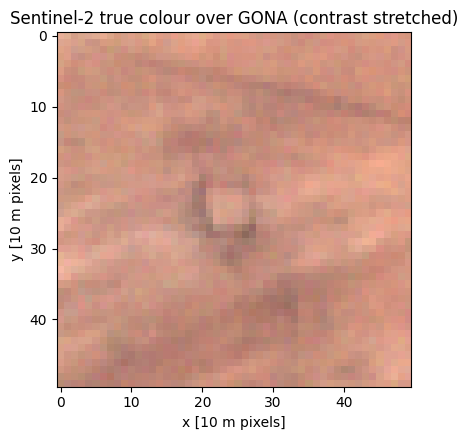

In [9]:
s2_10m = dt_mu["S2_MSI_L1C/10m"].dataset
rgb = np.dstack([s2_10m[band].values for band in ("B04", "B03", "B02")])

median = np.nanmedian(rgb, axis=(0, 1))              # the site's average colour
colour = 0.8 * median / median.max()                 # shown mid-bright, leaving room above and below
lo, hi = np.nanpercentile(rgb - median, [2, 98])     # pixel-to-pixel spread, one value for all bands
rgb = np.clip(colour + 0.2 * (rgb - median) / (hi - lo), 0, 1)

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.imshow(rgb)
ax.set(xlabel="x [10 m pixels]", ylabel="y [10 m pixels]", title=f"Sentinel-2 true colour over {SITE} (contrast stretched)")
plt.tight_layout()


##

### 3. Prepare the datasets for comparison
Before comparison, the datasets are aligned in space, time, and spectral response. This includes:

- Spatial averaging of the image measurements and their uncertainties over the site region of interest (ROI).
- Spectral band alignment between the Sentinel-2 and RadCalNet measurements.
- Temporal interpolation of the RadCalNet reflectance and uncertainty data to the Sentinel-2 acquisition time.

These steps ensure that the compared observations represent equivalent spectral, temporal, and spatial conditions. Uncertainties must be propagated through each processing step to quantify the uncertainty of the resulting comparison.

**Sentinel-2 ROI average, with uncertainty propagation**

Next we average each band over the pixels inside the site ROI, and propagate the uncertainties through that average with [`punpy`](https://github.com/comet-toolkit/punpy). `eoio` stores the uncertainty components it reads in the datasets with [`obsarray`](https://github.com/comet-toolkit/obsarray), together with how the errors of each component are correlated, and `punpy` uses this to run a Monte Carlo propagation through a measurement function, here the mean over the pixels inside the ROI.

In [10]:
import punpy
import shapely

S2_BANDS = ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B11", "B12"]  # B09 (water vapour) & B10 (cirrus) bands omitted

prop = punpy.MCPropagation(1000)  # Monte Carlo propagation with 1000 steps


class ROIMean(punpy.MeasurementFunction):
    """The mean of Sentinel-2 bands over the pixels inside the site ROI."""

    def meas_function(self, *bands):
        return np.array([np.nanmean(np.where(self.inside, band, np.nan)) for band in bands])


def roi_average(node, roi):
    """ROI-average the Sentinel-2 bands of one resolution node, propagating their uncertainties."""
    ds = node.to_dataset()
    bands = [name for name in ds.data_vars if name.startswith("B")]  # the band variables (B01, ..., B8A)
    mean = ROIMean(prop=prop, xvariables=bands, yvariable="reflectance", ydims=["band"], sizes_dict={"band": len(bands)})
    mean.inside = shapely.contains_xy(roi, ds["longitude"].values, ds["latitude"].values)
    out = mean.propagate_ds_total(ds)
    return out[["reflectance", "u_tot_reflectance"]].rename(u_tot_reflectance="u_total").assign_coords(band=bands)


roi = matchup.collocation_region  # the region where the two datasets overlap

# one node per pixel size (10 m, 20 m, 60 m); then select the bands we compare
s2 = xr.concat([roi_average(node, roi) for node in dt_mu["S2_MSI_L1C"].children.values()], dim="band").sel(band=S2_BANDS)
s2

<xarray.Dataset> Size: 264B
Dimensions:      (band: 11)
Coordinates:
  * band         (band) <U3 132B 'B01' 'B02' 'B03' 'B04' ... 'B8A' 'B11' 'B12'
Data variables:
    reflectance  (band) float32 44B 0.188 0.1892 0.2181 ... 0.3548 0.4272 0.3501
    u_total      (band) float64 88B 0.0003599 7.151e-05 ... 0.0003552 0.0003143

**RadCalNet: from a spectrum to Sentinel-2 bands**

To compare like with like, we need the RadCalNet spectrum as Sentinel-2 would see it. Two steps do this, which together form the measurement function that `punpy` propagates the RadCalNet uncertainty through:

1. **Band integration.** We integrate the RadCalNet spectrum over each Sentinel-2A band's spectral response function (SRF, from `pyspectral`), using `meteor_maths`.
2. **Time interpolation.** RadCalNet spectra are provided every 30 minutes, so we interpolate linearly between the two spectra either side of the Sentinel-2 acquisition.

The RadCalNet reader stores the reflectance uncertainty in the dataset with `obsarray`. It cannot sample inputs with missing values, so we first drop the wavelengths where RadCalNet has no data (around 1.9 µm and above 2.3 µm).

In [11]:
from meteor_maths.band_integration import band_int
from meteor_maths.band_integration.srf_utils import return_srf

PLATFORM = "Sentinel-2A"
SRFS = {band: return_srf(PLATFORM, "msi", band) for band in S2_BANDS}


def integrate_over_srf(wavelength, values, band):
    """Band-integrate a spectrum over one Sentinel-2A band's SRF."""
    srf, srf_wavelength = SRFS[band]
    covered = (srf_wavelength >= wavelength.min()) & (srf_wavelength <= wavelength.max())  # B12's SRF extends beyond the data
    return band_int(values, wavelength, srf[covered], srf_wavelength[covered])


class RCNInS2Bands(punpy.MeasurementFunction):
    """Band-integrate the two RadCalNet spectra either side of the overpass, and interpolate between them."""

    def meas_function(self, reflectance):
        before, after = reflectance[:, 0], reflectance[:, 1]
        return np.array(
            [
                (1 - self.weight) * integrate_over_srf(self.wavelength, before, band)
                + self.weight * integrate_over_srf(self.wavelength, after, band)
                for band in S2_BANDS
            ]
        )


def to_datetime64(time):
    """A (naive or timezone-aware) datetime as a UTC np.datetime64."""
    if time.tzinfo is not None:
        time = time.astimezone(datetime.timezone.utc).replace(tzinfo=None)
    return np.datetime64(time)


obs_time = to_datetime64(next(p.start_time for p in matchup.products if p.collection == "S2_MSI_L1C"))

times = rcn["time"].values
i_after = int(np.searchsorted(times, obs_time))  # the first RadCalNet spectrum after the overpass
pair = rcn[["reflectance", "reflectance_uncertainty"]].isel(time=[i_after - 1, i_after]).dropna("wavelength", how="any")

rcn_in_s2 = RCNInS2Bands(prop=prop, xvariables=["reflectance"], yvariable="reflectance", ydims=["band"], sizes_dict={"band": len(S2_BANDS)})
rcn_in_s2.wavelength = pair["wavelength"].values
rcn_in_s2.weight = float((obs_time - times[i_after - 1]) / (times[i_after] - times[i_after - 1]))  # weight of the later spectrum

out = rcn_in_s2.propagate_ds_total(pair)
centres = [np.sum(SRFS[band][0] * SRFS[band][1]) / np.sum(SRFS[band][0]) for band in S2_BANDS]  # SRF-weighted band centres [nm]
rcn_s2 = (
    out[["reflectance", "u_tot_reflectance"]]
    .rename(u_tot_reflectance="u_total")
    .assign_coords(band=S2_BANDS, centre_nm=("band", centres))
)
print(f"Sentinel-2 acquisition: {obs_time}; RadCalNet spectra used: {times[i_after - 1]} and {times[i_after]}")
rcn_s2

6kB [00:05,  1.07kB/s]


Sentinel-2 acquisition: 2026-05-15T08:47:31.000000; RadCalNet spectra used: 2026-05-15T08:30:00.000000000 and 2026-05-15T09:00:00.000000000


<xarray.Dataset> Size: 396B
Dimensions:      (band: 11)
Coordinates:
  * band         (band) <U3 132B 'B01' 'B02' 'B03' 'B04' ... 'B8A' 'B11' 'B12'
    centre_nm    (band) float64 88B 442.7 492.7 559.8 ... 1.614e+03 2.202e+03
Data variables:
    reflectance  (band) float64 88B 0.1949 0.1964 0.2245 ... 0.4351 0.3611
    u_total      (band) float64 88B 0.00353 0.004527 ... 0.01341 0.01139

### 4. Compare observations with uncertainties

Now we have both datasets in the same bands, with an uncertainty on each. We first plot them together. The RadCalNet spectrum in the background is the (time-interpolated) full-resolution spectrum, and the points with error bars are the band-integrated RadCalNet values and the Sentinel-2 ROI means (coverage factor k=2).

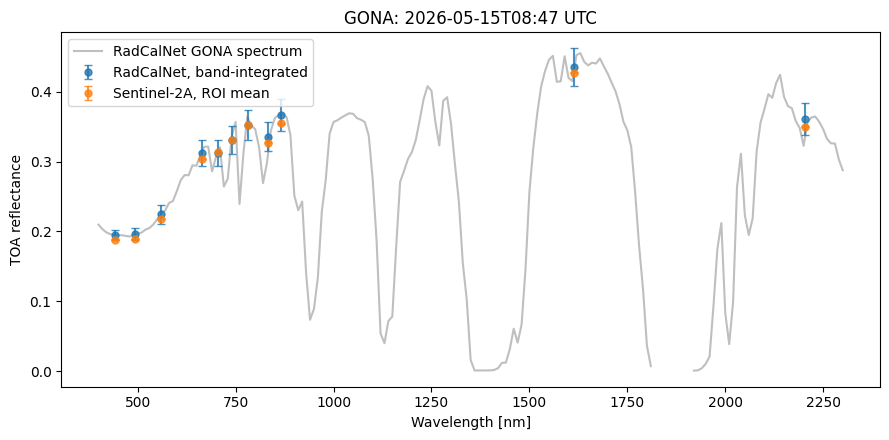

In [12]:
full_spectrum = rcn["reflectance"].interp(time=obs_time)  # the full-resolution spectrum at the time of the overpass

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(full_spectrum["wavelength"], full_spectrum, color="0.75", label="RadCalNet GONA spectrum")
ax.errorbar(
    rcn_s2["centre_nm"], rcn_s2["reflectance"], 2*rcn_s2["u_total"],
    fmt="o", color="C0", alpha=0.8, markersize=5, capsize=3, label="RadCalNet, band-integrated",
)
ax.errorbar(
    rcn_s2["centre_nm"], s2["reflectance"], 2*s2["u_total"],
    fmt="o", color="C1", alpha=0.8, markersize=5, capsize=3, label="Sentinel-2A, ROI mean",
)
ax.set(xlabel="Wavelength [nm]", ylabel="TOA reflectance", title=f"{SITE}: {obs_time.astype('datetime64[m]')} UTC")
ax.legend()
plt.tight_layout()

To see how well they agree, we compute the relative difference $(\rho_{S2} - \rho_{RCN})/\rho_{RCN}$ for each band. The two uncertainties are independent (different instruments, different methods), so they combine in quadrature, and we show the result with a coverage factor of k=2. Where the error bars include zero, the two agree within their stated uncertainties.

<xarray.Dataset> Size: 539B
Dimensions:         (band: 11)
Coordinates:
  * band            (band) <U3 132B 'B01' 'B02' 'B03' ... 'B8A' 'B11' 'B12'
    centre_nm       (band) float64 88B 442.7 492.7 559.8 ... 1.614e+03 2.202e+03
Data variables:
    S2              (band) float32 44B 0.188 0.1892 0.2181 ... 0.4272 0.3501
    RadCalNet       (band) float64 88B 0.1949 0.1964 0.2245 ... 0.4351 0.3611
    difference [%]  (band) float64 88B -3.561 -3.687 -2.847 ... -1.803 -3.058
    unc. (k=2) [%]  (band) float64 88B 3.513 4.441 5.882 ... 6.046 6.053 6.117
    agree           (band) bool 11B False True True True ... True True True True

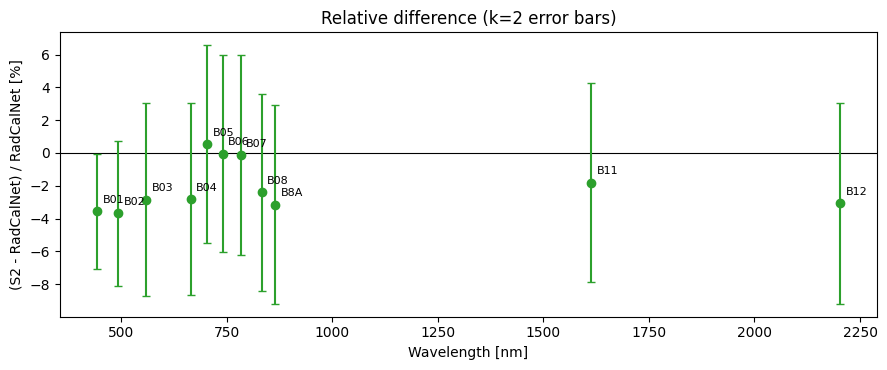

In [13]:
ratio = s2["reflectance"] / rcn_s2["reflectance"]
difference = 100 * (ratio - 1)
u_difference = 100 * ratio * np.hypot(s2["u_total"] / s2["reflectance"], rcn_s2["u_total"] / rcn_s2["reflectance"])

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.axhline(0, color="k", lw=0.8)
ax.errorbar(rcn_s2["centre_nm"], difference, 2*u_difference, fmt="o", color="C2", capsize=3)
for band, x_nm, y_pct in zip(S2_BANDS, rcn_s2["centre_nm"].values, difference.values):
    ax.annotate(band, (x_nm, y_pct), textcoords="offset points", xytext=(4, 6), fontsize=8)
ax.set(xlabel="Wavelength [nm]", ylabel="(S2 - RadCalNet) / RadCalNet [%]", title="Relative difference (k=2 error bars)")
plt.tight_layout()

xr.Dataset(
    {
        "S2": s2["reflectance"],
        "RadCalNet": rcn_s2["reflectance"],
        "difference [%]": difference,
        "unc. (k=2) [%]": 2 * u_difference,
        "agree": np.abs(difference) <= 2 * u_difference,
    }
)

**Where next?**

We compared a single overpass, but the same steps scale up: change the time window in the context to find many matchups, loop over the events in the catalogue, and collect the differences per band to look at biases over time. The other collections that `scrappi` and `eoio` support (Landsat, Sentinel-3, ...) and the other RadCalNet sites can be used by changing the `platforms` and `collections` of the context. Matchup catalogues can also be shared through a central STAC catalogue, see the `eomatch` documentation.

More about the tools: [MetEOR toolkit](https://www.comet-toolkit.org/meteor/).